# 07. Cenários e resultados

Treina o modelo congelado (ExtraTrees) a cada sexta-feira, mede cenários e históricos e testa se houve vazamento. O código está em `funcoes/validacao.py` e `funcoes/modelos.py`.

In [1]:
from funcoes.configuracao import ENTRADAS, PASTA_MODELOS, executar_se_preciso

RECALCULAR = False  # True refaz os treinos, mesmo sem mudanca nos dados ou no codigo
from funcoes.validacao import avaliar_cenarios, avaliar_historicos, consolidar_resultados
from funcoes.verificacoes import testar_vazamento_modelos

executar_se_preciso(avaliar_cenarios, RECALCULAR, [PASTA_MODELOS / "previsoes_validacao.parquet"], ENTRADAS["cenarios"])
executar_se_preciso(avaliar_historicos, RECALCULAR, [PASTA_MODELOS / "previsoes_janelas_treino.parquet"], ENTRADAS["cenarios"])
consolidar_resultados()

Base do cenario 4: C2 campeao
janela          cenario  modelo   mae
    t1               C1 campeao 20.70
    t1               C2 campeao 20.87
    t1               C3 campeao 21.12
    t1 S_clima_perfeito campeao 21.02
    t2               C1 campeao 20.80
    t2               C2 campeao 20.54
    t2 S_clima_perfeito campeao 20.67


periodo                              escolha_2025                                            prospectiva_set_out                                            prova_2026                                           
janela_treino                               1_ano 2_anos 6_meses ano_anterior_e_atual   tudo               1_ano 2_anos 6_meses ano_anterior_e_atual   tudo      1_ano 2_anos 6_meses ano_anterior_e_atual   tudo
janela cenario modelo                                                                                                                                                                                            
t1     C1      arvores                      20.72  21.85   20.96                21.89  21.81               16.04  15.14   12.89                13.86  14.14      28.45  28.33   33.16                29.48  26.57
               campeao                      20.60  20.92   21.23                21.15  20.70               13.54  15.57   19.68                15.04  15.29     

janela cenario  modelo janela_treino   mae
    t1      C1 campeao         1_ano 20.60
    t1      C2 campeao         1_ano 20.65
    t1      C3 campeao         1_ano 20.70
    t1       H campeao         1_ano 21.16
    t2      C1 campeao         1_ano 20.70
    t2      C2 campeao         1_ano 20.93
    t2       H campeao         1_ano 21.67
base do cenario 4: C2 | metodo: previsao_adaptativa {'previsao_50_50': np.float64(20.22), 'previsao_adaptativa': np.float64(20.18)}
         janela      universo    alternativa  dias   mae  rmse   r2  vies  excesso  deficit  dias_deficit  dif_referencia  ic_inf  ic_sup
             t1  sem_atipicos          plano   121 24.12 34.47 0.47 13.16   2255.0    663.0         39.67             NaN     NaN     NaN
             t1  sem_atipicos consumo_tipico   121 31.31 42.69 0.18  1.13   1963.0   1826.0         57.02            7.20   -0.65   15.73
             t1  sem_atipicos      mesmo_dia   121 28.66 41.74 0.22  0.99   1794.0   1674.0         56.20     

## Exemplo de uma sexta-feira no walk-forward

O treino termina antes da sexta-feira, e a previsão vale para a semana seguinte.

In [2]:
import pandas as pd

from funcoes.configuracao import CAMPEAO, CENARIO_CAMPEAO, CENARIOS, GOLD
from funcoes.modelos import dados_de_treino, prever_emissao

gold = pd.read_parquet(GOLD / "gold_t1.parquet")
origem = pd.Timestamp("2026-03-06")
treino = dados_de_treino(gold, origem, CENARIOS[CENARIO_CAMPEAO], 12)
print(f"Treino: {treino['data'].min().date()} a {treino['data'].max().date()}, {len(treino)} dias")
alvo = gold[gold["origem"] == origem][["data", "nivel_base", "consumo"]].assign(previsao=prever_emissao(gold, origem, CENARIOS[CENARIO_CAMPEAO], CAMPEAO, 12).round())
alvo

Treino: 2025-03-06 a 2026-03-05, 178 dias


,data,nivel_base,consumo,previsao
560,2026-03-09,192.00,182.0,216.0
561,2026-03-10,170.00,145.0,168.0
562,2026-03-11,168.75,162.0,194.0
563,2026-03-12,156.50,91.0,145.0
564,2026-03-13,158.25,128.0,144.0


## Teste de vazamento dos modelos

Embaralha o futuro e exige previsão idêntica.

In [3]:
if RECALCULAR:
    testar_vazamento_modelos()

In [4]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from funcoes.nomes import ALTERNATIVAS, CENARIOS, HISTORICOS, JANELAS, MODELOS, UNIVERSOS, rotulo

pd.set_option("display.max_rows", 90, "display.max_columns", 30, "display.width", 180, "display.max_colwidth", 60)
RESULTADOS = Path("..") / "resultados" / "modelos"
FIGURAS = Path("..") / "resultados" / "figuras"

SUPERFICIE, TEXTO2, GRADE = "#fcfcfb", "#52514e", "#e6e5e0"
AZUL, LARANJA, AQUA, VIOLETA, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#9b9a93"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE, "axes.edgecolor": GRADE,
    "axes.labelcolor": TEXTO2, "xtick.color": TEXTO2, "ytick.color": TEXTO2, "axes.grid": True, "grid.color": GRADE,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True, "font.size": 10,
})

def ler(nome):
    return pd.read_csv(RESULTADOS / f"{nome}.csv", sep=";", encoding="utf-8-sig")

resultado, escolhas, janelas, metricas = ler("resultado_final"), ler("configuracao_escolhida"), ler("comparacao_janelas_treino"), ler("metricas_janelas_treino")
preparo = pd.read_parquet(RESULTADOS / "preparo_diario_final.parquet")
compras = pd.read_parquet(RESULTADOS / "compras_diario_final.parquet")

def intervalo(linha):
    return "" if pd.isna(linha["ic_inf"]) else f"{linha['ic_inf']:.1f} a {linha['ic_sup']:.1f}"

def tabela(janela, periodo, universo, nome_ref):
    d = resultado[(resultado["janela"] == janela) & (resultado["periodo"] == periodo) & (resultado["universo"] == universo)].copy()
    d["Intervalo de 95%"] = d.apply(intervalo, axis=1)
    d["alternativa"] = d["alternativa"].map(ALTERNATIVAS)
    colunas = {"alternativa": "Alternativa", "mae": rotulo("mae"), "vies": rotulo("vies"), "excesso": rotulo("excesso"), "deficit": rotulo("deficit"),
               "dias_deficit": "% de dias com déficit potencial", "dif_referencia": f"Diferença para {nome_ref}", "Intervalo de 95%": "Intervalo de 95%"}
    return d[list(colunas)].rename(columns=colunas).round(1).reset_index(drop=True)

## 1. Quanto histórico usar para aprender

Cada linha é o modelo congelado com um histórico diferente. Menor erro médio é melhor.

In [5]:
base = metricas[(metricas["universo"] == "sem_atipicos")].merge(escolhas[["janela", "cenario", "modelo"]], on=["janela", "cenario", "modelo"])
tab = base.pivot_table(index=["janela", "cenario"], columns=["periodo", "janela_treino"], values="mae").round(1)
tab = tab.rename(columns=HISTORICOS, level=1).rename(columns={"escolha_2025": "Escolha em 2025", "prova_2026": "Desenvolvimento, fev. a ago. de 2026", "prospectiva_set_out": "Prospectiva, set. e out. de 2026"}, level=0)
tab.rename(index=JANELAS, level=0).rename(index=CENARIOS, level=1).rename_axis(index=["Decisão", "Cenário"], columns=["Período", "Histórico"])

Período                                                               Escolha em 2025                                                                                              \
Histórico                                                            Últimos 12 meses Últimos 2 anos Últimos 6 meses Ano anterior + ano atual até agora Todo o histórico anterior   
Decisão                        Cenário                                                                                                                                              
Preparo (semana seguinte)      Cenário 1: consumo e calendário                   20.6           20.9            21.2                               21.2                      20.7   
                               Cenário 2: inclui o cardápio                      20.6           20.9            21.2                               21.2                      20.9   
                               Cenário 3: inclui a previsão do tempo             20.7           21.1            20.9                               21.1                      21.1   
                               H                                                 21.2           22.2            21.2                               22.0                      22.1   
Compras (daqui a duas semanas) Cenário 1: consumo e calendário                   20.7           21.2            22.6                               21.5                      20.8   
                               Cenário 2: inclui o cardápio                      20.9           20.9            22.6                               21.5                      20.5   
                               H                                                 21.7           22.1            22.0                               22.3                      21.7   

Período                                                              Prospectiva, set. e out. de 2026                                                                    \
Histórico                                                                            Últimos 12 meses Últimos 2 anos Últimos 6 meses Ano anterior + ano atual até agora   
Decisão                        Cenário                                                                                                                                    
Preparo (semana seguinte)      Cenário 1: consumo e calendário                                   13.5           15.6            19.7                               15.0   
                               Cenário 2: inclui o cardápio                                      13.2           15.5            19.2                               14.5   
                               Cenário 3: inclui a previsão do tempo                             14.1           15.9            18.5                               15.1   
                               H                                                                 13.5           14.5            13.0                               13.4   
Compras (daqui a duas semanas) Cenário 1: consumo e calendário                                   13.2           17.2            19.4                               13.9   
                               Cenário 2: inclui o cardápio                                      13.8           17.5            19.5                               13.8   
                               H                                                                 15.2           18.6            16.2                               14.9   

Período                                                                                        Desenvolvimento, fev. a ago. de 2026                                 \
Histórico                                                            Todo o histórico anterior                     Últimos 12 meses Últimos 2 anos Últimos 6 meses   
Decisão                        Cenário                                                                                                            

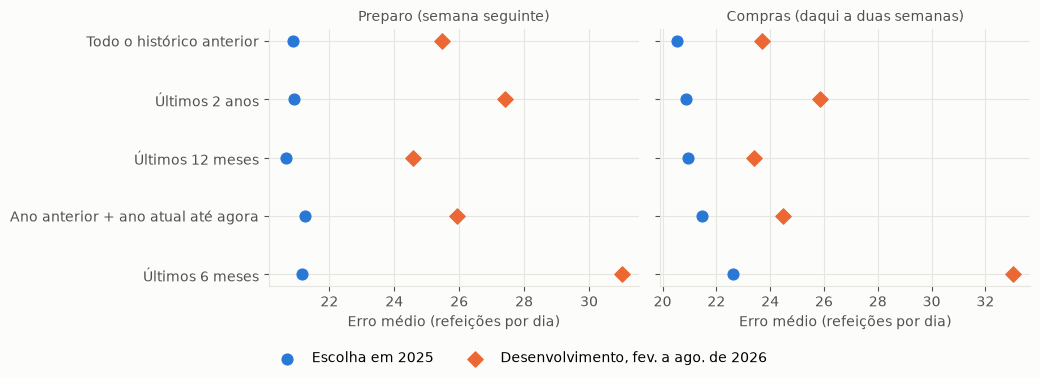

,Decisão,Cenário,Últimos 12 meses contra,Diferença (refeições por dia),Intervalo de 95%
0,Preparo (semana seguinte),Cenário 1: consumo e calendário,Últimos 2 anos,-2.7,-4.6 a -0.9
1,Preparo (semana seguinte),Cenário 1: consumo e calendário,Últimos 6 meses,-5.9,-12.0 a -1.7
2,Preparo (semana seguinte),Cenário 1: consumo e calendário,Ano anterior + ano atual até agora,-0.9,-2.0 a 0.0
3,Preparo (semana seguinte),Cenário 1: consumo e calendário,Todo o histórico anterior,-0.7,-2.9 a 1.3
4,Preparo (semana seguinte),Cenário 2: inclui o cardápio,Últimos 2 anos,-2.8,-4.7 a -1.1
5,Preparo (semana seguinte),Cenário 2: inclui o cardápio,Últimos 6 meses,-6.4,-12.4 a -2.1
6,Preparo (semana seguinte),Cenário 2: inclui o cardápio,Ano anterior + ano atual até agora,-1.3,-3.0 a -0.1
7,Preparo (semana seguinte),Cenário 2: inclui o cardápio,Todo o histórico anterior,-0.9,-3.7 a 1.7
8,Preparo (semana seguinte),Cenário 3: inclui a previsão do tempo,Últimos 2 anos,-2.4,-4.2 a -0.6
9,Preparo (semana seguinte),Cenário 3: inclui a previsão do tempo,Últimos 6 meses,-6.4,-12.5 a -2.1


In [6]:
ordem = ["tudo", "2_anos", "1_ano", "ano_anterior_e_atual", "6_meses"]
fig, eixos = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, (janela, cenario) in zip(eixos, [("t1", "C2"), ("t2", "C2")]):
    d = base[(base["janela"] == janela) & (base["cenario"] == cenario)].set_index("janela_treino")
    p25 = d[d["periodo"] == "escolha_2025"]["mae"].reindex(ordem)
    p26 = d[d["periodo"] == "prova_2026"]["mae"].reindex(ordem)
    y = range(len(ordem))
    ax.scatter(p25, y, s=60, color=AZUL, label="Escolha em 2025", zorder=3)
    ax.scatter(p26, y, s=60, color=LARANJA, marker="D", label="Desenvolvimento, fev. a ago. de 2026", zorder=3)
    ax.set_yticks(list(y), [HISTORICOS[o] for o in ordem])
    ax.invert_yaxis() if ax is eixos[0] else None
    ax.set_title(JANELAS[janela], fontsize=10, color=TEXTO2)
    ax.set_xlabel("Erro médio (refeições por dia)")
fig.legend(*eixos[0].get_legend_handles_labels(), frameon=False, loc="lower center", ncol=2)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(FIGURAS / "06_historico_de_treino.png", dpi=200)
plt.show()

c = janelas.assign(Decisão=janelas["janela"].map(JANELAS), Cenário=janelas["cenario"].map(CENARIOS), Comparado_com=janelas["comparada"].map(HISTORICOS))
c["Diferença (refeições por dia)"] = c["dif"].round(1)
c["Intervalo de 95%"] = c.apply(intervalo, axis=1)
c[["Decisão", "Cenário", "Comparado_com", "Diferença (refeições por dia)", "Intervalo de 95%"]].rename(columns={"Comparado_com": "Últimos 12 meses contra"})

## 2. Modelo congelado em cada cenário

In [7]:
e = escolhas.assign(Decisão=escolhas["janela"].map(JANELAS), Cenário=escolhas["cenario"].map(CENARIOS), Modelo=escolhas["modelo"].map(MODELOS),
                    Histórico=escolhas["janela_treino"].map(HISTORICOS), Erro_em_2025=escolhas["mae"].round(1))
e[["Decisão", "Cenário", "Modelo", "Histórico", "Erro_em_2025"]].rename(columns={"Erro_em_2025": "Erro médio em 2025"})

,Decisão,Cenário,Modelo,Histórico,Erro médio em 2025
0,Preparo (semana seguinte),Cenário 1: consumo e calendário,ExtraTrees,Últimos 12 meses,20.6
1,Preparo (semana seguinte),Cenário 2: inclui o cardápio,ExtraTrees,Últimos 12 meses,20.6
2,Preparo (semana seguinte),Cenário 3: inclui a previsão do tempo,ExtraTrees,Últimos 12 meses,20.7
3,Preparo (semana seguinte),NaN,ExtraTrees,Últimos 12 meses,21.2
4,Compras (daqui a duas semanas),Cenário 1: consumo e calendário,ExtraTrees,Últimos 12 meses,20.7
5,Compras (daqui a duas semanas),Cenário 2: inclui o cardápio,ExtraTrees,Últimos 12 meses,20.9
6,Compras (daqui a duas semanas),NaN,ExtraTrees,Últimos 12 meses,21.7


## 3. Preparo: fevereiro a agosto de 2026

Comparação com o quantitativo da nutricionista, nas mesmas datas. O quantitativo chega na sexta-feira à tarde, com a mesma antecedência da previsão.

In [8]:
for universo in ("sem_atipicos", "todos_os_dias"):
    print(UNIVERSOS[universo])
    display(tabela("t1", "prova_2026", universo, "a nutricionista"))

Sem dias atípicos


,Alternativa,Erro médio (refeições por dia),Tendência (+ acima do consumo; - abaixo do consumo),Excesso potencial (refeições),Déficit potencial (refeições),% de dias com déficit potencial,Diferença para a nutricionista,Intervalo de 95%
0,Quantitativo da nutricionista,24.1,13.2,2255.0,663.0,39.7,NaN,
1,Consumo de referência,31.3,1.1,1963.0,1826.0,57.0,7.2,-0.7 a 15.7
2,NaN,28.7,1.0,1794.0,1674.0,56.2,4.5,-3.6 a 13.7
3,Só histórico de consumo,29.8,-1.3,1725.0,1877.0,62.0,5.7,-1.9 a 13.4
4,Cenário 1: consumo e calendário,25.1,1.5,1610.0,1426.0,51.2,1.0,-4.8 a 6.8
5,Cenário 2: inclui o cardápio,24.6,1.1,1557.0,1418.0,52.1,0.5,-5.4 a 6.2
6,Cenário 3: inclui a previsão do tempo,24.6,1.4,1570.0,1406.0,52.9,0.5,-5.3 a 6.3
7,Cenário 4: inclui o quantitativo da nutricionista,20.4,7.9,1714.0,757.0,43.8,-3.7,-7.1 a -0.2


Todos os dias


,Alternativa,Erro médio (refeições por dia),Tendência (+ acima do consumo; - abaixo do consumo),Excesso potencial (refeições),Déficit potencial (refeições),% de dias com déficit potencial,Diferença para a nutricionista,Intervalo de 95%
0,Quantitativo da nutricionista,26.2,15.4,2561.0,663.0,39.0,NaN,
1,Consumo de referência,33.3,3.7,2276.0,1826.0,56.1,7.1,-0.7 a 15.6
2,NaN,31.0,3.7,2133.0,1674.0,55.3,4.7,-3.3 a 13.7
3,Só histórico de consumo,31.6,1.1,2010.0,1877.0,61.0,5.4,-2.0 a 13.1
4,Cenário 1: consumo e calendário,27.4,4.2,1942.0,1426.0,50.4,1.2,-4.6 a 6.8
5,Cenário 2: inclui o cardápio,26.9,3.8,1890.0,1418.0,51.2,0.7,-5.2 a 6.4
6,Cenário 3: inclui a previsão do tempo,26.9,4.0,1901.0,1406.0,52.0,0.7,-5.1 a 6.4
7,Cenário 4: inclui o quantitativo da nutricionista,22.8,10.5,2043.0,757.0,43.1,-3.4,-6.9 a -0.0


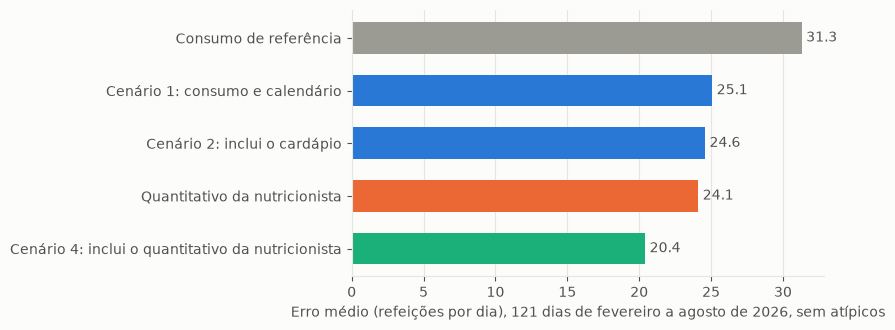

In [9]:
d = resultado[(resultado["janela"] == "t1") & (resultado["periodo"] == "prova_2026") & (resultado["universo"] == "sem_atipicos")].set_index("alternativa")
ordem = ["consumo_tipico", "C1", "C2", "plano", "C4"]
fig, ax = plt.subplots(figsize=(8.5, 3.4))
cores = [CINZA, AZUL, AZUL, LARANJA, AQUA]
ax.barh([ALTERNATIVAS[o] for o in ordem], d.loc[ordem, "mae"], height=0.6, color=cores)
for y, o in enumerate(ordem):
    ax.text(d.loc[o, "mae"] + 0.3, y, f"{d.loc[o, 'mae']:.1f}", va="center", color=TEXTO2)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel(f"Erro médio (refeições por dia), {int(d['dias'].iloc[0])} dias de fevereiro a agosto de 2026, sem atípicos")
fig.tight_layout()
fig.savefig(FIGURAS / "07_preparo_prova_2026.png", dpi=200)
plt.show()

### Mês a mês

O resultado não é uniforme: o artefato e a nutricionista erram em momentos diferentes, e é isso que dá valor ao híbrido.

In [10]:
p = preparo[(preparo["periodo"] == "prova_2026") & preparo["consumo"].notna()].copy()
p["Mês"] = p["data"].dt.strftime("%Y-%m")
mensal = p.groupby("Mês").apply(lambda g: pd.Series({
    "Dias": len(g), "Nutricionista": (g["plano"] - g["consumo"]).abs().mean(), "Artefato (cenário 2)": (g["C2"] - g["consumo"]).abs().mean(),
    "Híbrido (cenário 4)": (g["C4"] - g["consumo"]).abs().mean()}), include_groups=False).round(1)
mensal

,Dias,Nutricionista,Artefato (cenário 2),Híbrido (cenário 4)
Mês,,,,
2026-02,14.0,25.4,31.3,21.3
2026-03,22.0,23.6,31.7,18.2
2026-04,19.0,16.3,15.3,13.2
2026-05,18.0,31.9,21.6,23.4
2026-06,20.0,32.8,22.7,23.0
2026-07,9.0,33.2,52.9,48.8
2026-08,21.0,24.2,26.9,25.3


## 4. Compras: fevereiro a agosto de 2026

Não existe quantitativo com duas semanas de antecedência, então a referência é o consumo de referência.

In [11]:
for universo in ("sem_atipicos", "todos_os_dias"):
    print(UNIVERSOS[universo])
    display(tabela("t2", "prova_2026", universo, "o consumo de referência"))

Sem dias atípicos


,Alternativa,Erro médio (refeições por dia),Tendência (+ acima do consumo; - abaixo do consumo),Excesso potencial (refeições),Déficit potencial (refeições),% de dias com déficit potencial,Diferença para o consumo de referência,Intervalo de 95%
0,Consumo de referência,31.6,-0.7,1870.0,1959.0,62.8,NaN,
1,NaN,29.0,-0.5,1726.0,1786.0,62.0,-2.6,-4.8 a -0.5
2,Só histórico de consumo,30.3,-1.9,1722.0,1946.0,63.6,-1.3,-3.8 a 1.3
3,Cenário 1: consumo e calendário,24.0,-0.3,1435.0,1466.0,53.7,-7.7,-13.5 a -3.7
4,Cenário 2: inclui o cardápio,23.4,-0.5,1383.0,1449.0,56.2,-8.2,-14.3 a -4.3


Todos os dias


,Alternativa,Erro médio (refeições por dia),Tendência (+ acima do consumo; - abaixo do consumo),Excesso potencial (refeições),Déficit potencial (refeições),% de dias com déficit potencial,Diferença para o consumo de referência,Intervalo de 95%
0,Consumo de referência,33.6,1.8,2178.0,1959.0,61.8,NaN,
1,NaN,31.3,2.2,2058.0,1786.0,61.0,-2.4,-4.5 a -0.2
2,Só histórico de consumo,32.3,0.6,2022.0,1946.0,62.6,-1.4,-3.9 a 1.2
3,Cenário 1: consumo e calendário,26.4,2.6,1780.0,1466.0,52.8,-7.2,-13.0 a -3.3
4,Cenário 2: inclui o cardápio,25.7,2.2,1714.0,1449.0,55.3,-7.9,-13.8 a -4.1


## 5. O algoritmo contra o consumo de referência, no preparo

In [12]:
tabela("t1_vs_tipico", "prova_2026", "sem_atipicos", "o consumo de referência")

,Alternativa,Erro médio (refeições por dia),Tendência (+ acima do consumo; - abaixo do consumo),Excesso potencial (refeições),Déficit potencial (refeições),% de dias com déficit potencial,Diferença para o consumo de referência,Intervalo de 95%
0,Consumo de referência,31.3,1.1,1963.0,1826.0,57.0,NaN,
1,Só histórico de consumo,29.8,-1.3,1725.0,1877.0,62.0,-1.5,-3.7 a 0.7
2,Cenário 1: consumo e calendário,25.1,1.5,1610.0,1426.0,51.2,-6.2,-12.0 a -2.4
3,Cenário 2: inclui o cardápio,24.6,1.1,1557.0,1418.0,52.1,-6.7,-12.4 a -2.9
4,Cenário 3: inclui a previsão do tempo,24.6,1.4,1570.0,1406.0,52.9,-6.7,-12.5 a -3.0


## 6. Limites desta avaliação

- Os excessos e déficits são diferenças entre plano e consumo registrado. Não medem descarte nem pessoas sem refeição.
- A avaliação cobre um ano só e um único restaurante.
- 2026 já tinha sido observado nas etapas exploratórias do projeto; a confirmação independente depende de previsões guardadas antes do serviço.
- O cenário 3 ficou fora do comitê porque não reduziu o erro em 2025, e a previsão do tempo segue disponível como alerta.
- O cenário 4 usa os pesos aprendidos em cada ano; em fevereiro de 2026 ainda não há histórico do quantitativo, e o peso começa em 50%.

## Avaliação prospectiva: setembro e outubro de 2026

Este período fica separado dos resultados até agosto.

In [13]:
for universo in ("sem_atipicos", "todos_os_dias"):
    print(UNIVERSOS[universo])
    display(tabela("t1", "prospectiva_set_out", universo, "a nutricionista"))
    display(tabela("t2", "prospectiva_set_out", universo, "o consumo de referência"))

Sem dias atípicos


,Alternativa,Erro médio (refeições por dia),Tendência (+ acima do consumo; - abaixo do consumo),Excesso potencial (refeições),Déficit potencial (refeições),% de dias com déficit potencial,Diferença para a nutricionista,Intervalo de 95%
0,Quantitativo da nutricionista,22.1,-1.5,289.0,331.0,39.3,NaN,
1,Consumo de referência,13.6,0.2,194.0,188.0,50.0,-8.5,-20.9 a 1.4
2,NaN,15.4,-0.4,210.0,220.0,60.7,-6.8,-20.1 a 3.5
3,Só histórico de consumo,13.5,3.3,235.0,142.0,53.6,-8.7,-21.3 a 0.7
4,Cenário 1: consumo e calendário,13.5,6.1,275.0,104.0,35.7,-8.6,-24.5 a 2.4
5,Cenário 2: inclui o cardápio,13.2,2.1,214.0,156.0,50.0,-8.9,-23.4 a 2.2
6,Cenário 3: inclui a previsão do tempo,14.1,2.7,236.0,160.0,46.4,-8.0,-22.5 a 3.5
7,Cenário 4: inclui o quantitativo da nutricionista,18.3,-0.9,244.0,268.0,42.9,-3.9,-9.1 a 0.2


,Alternativa,Erro médio (refeições por dia),Tendência (+ acima do consumo; - abaixo do consumo),Excesso potencial (refeições),Déficit potencial (refeições),% de dias com déficit potencial,Diferença para o consumo de referência,Intervalo de 95%
0,Consumo de referência,13.9,-1.1,180.0,210.0,53.6,NaN,
1,NaN,14.7,-2.0,178.0,234.0,64.3,0.8,-1.4 a 3.1
2,Só histórico de consumo,15.2,-1.0,199.0,227.0,50.0,1.3,-0.7 a 2.9
3,Cenário 1: consumo e calendário,13.2,1.0,198.0,171.0,60.7,-0.8,-4.6 a 2.8
4,Cenário 2: inclui o cardápio,13.8,-0.7,183.0,202.0,60.7,-0.2,-3.6 a 3.1


Todos os dias


,Alternativa,Erro médio (refeições por dia),Tendência (+ acima do consumo; - abaixo do consumo),Excesso potencial (refeições),Déficit potencial (refeições),% de dias com déficit potencial,Diferença para a nutricionista,Intervalo de 95%
0,Quantitativo da nutricionista,39.5,19.4,972.0,331.0,33.3,NaN,
1,Consumo de referência,30.7,19.3,824.0,188.0,42.4,-8.8,-19.3 a -1.1
2,NaN,31.8,18.5,830.0,220.0,51.5,-7.7,-18.8 a 1.0
3,Só histórico de consumo,31.2,22.5,886.0,142.0,45.5,-8.3,-19.0 a 0.0
4,Cenário 1: consumo e calendário,30.5,24.2,904.0,104.0,30.3,-8.9,-22.2 a 0.0
5,Cenário 2: inclui o cardápio,30.3,20.8,843.0,156.0,42.4,-9.2,-21.5 a -0.1
6,Cenário 3: inclui a previsão do tempo,31.2,21.5,870.0,160.0,39.4,-8.3,-20.6 a 0.9
7,Cenário 4: inclui o quantitativo da nutricionista,35.7,19.5,911.0,268.0,36.4,-3.8,-8.3 a -0.4


,Alternativa,Erro médio (refeições por dia),Tendência (+ acima do consumo; - abaixo do consumo),Excesso potencial (refeições),Déficit potencial (refeições),% de dias com déficit potencial,Diferença para o consumo de referência,Intervalo de 95%
0,Consumo de referência,30.2,17.5,787.0,210.0,45.5,NaN,
1,NaN,30.0,15.8,757.0,234.0,54.5,-0.2,-3.3 a 2.4
2,Só histórico de consumo,32.0,18.2,828.0,227.0,42.4,1.8,-0.1 a 3.4
3,Cenário 1: consumo e calendário,30.1,19.8,823.0,171.0,51.5,-0.1,-3.0 a 2.7
4,Cenário 2: inclui o cardápio,30.5,18.2,804.0,202.0,51.5,0.3,-2.4 a 2.9
